In [12]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [ ]:
import pandas as pd
import numpy as np

data = {
 'trip_id': ['T001','T002','T003','T004','T005','T006','T007','T008','T009','T010'],
 'mode': ['Taxi','Bus','Bike','Taxi','bus','Taxi','Bike','Bus','Taxi','Taxi'],
 'distance_km': [8.4,6.1,3.2,2.7,14.3,5.1,4.0,9.8,32.0,-1.5],
 'fare_cad': [19.5,3.75,0,11.2,3.75,13.2,0,3.75,72.0,15.0],
 'wait_min': [6,9,4,12,18,np.nan,3,11,55,8],
 'rating': [4,3,5,2,2,4,5,np.nan,1,3],
 'peak': ['No','Yes','No','Yes','Yes','No','No','Yes','Yes','Yes']
}

df = pd.DataFrame(data)


In [2]:
clean = df.copy()

# Standardize category labels
clean["mode"] = clean["mode"].str.title()

# Impossible negative distance -> missing
clean.loc[clean["distance_km"] < 0, "distance_km"] = np.nan

In [3]:
# 1. Which columns have missing values or inconsistent categories?

clean.isna().sum()

trip_id        0
mode           0
distance_km    1
fare_cad       0
wait_min       1
rating         1
peak           0
dtype: int64

wait_min and rating contain missing values. The mode column contains inconsistent capitalization (Bus vs. bus). After applying the domain rule that distance cannot be negative, distance_km also contains one missing value.

In [ ]:
# 2. Which observations violate obvious domain rules? What will you do with them?



| Observation | Issue | Action |
|---|---|---|
| T005 | `bus` vs `Bus` | Correct capitalization |
| T006 | missing wait | Keep row; retain missing |
| T008 | missing rating | Keep row; retain missing |
| T009 | extreme distance/fare/wait | Flag and investigate |
| T010 | negative distance | Set distance to missing / investigate |
| Bike fare = 0 | unusual but plausible | Keep unless domain rules say otherwise |

In [5]:
# 3. How do wait times differ across modes and peak/off-peak periods?

# By mode
clean.groupby("mode")["wait_min"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
mode,,,,,
Bike,2,3.500000,3.5,3.0,4.0
Bus,3,12.666667,11.0,9.0,18.0
Taxi,4,20.250000,10.0,6.0,55.0


In [6]:
# Peak vs Off-Peak

clean.groupby("peak")["wait_min"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
peak,,,,,
No,3,4.333333,4.0,3.0,6.0
Yes,6,18.833333,11.5,8.0,55.0


Waiting times are higher during peak periods even after removing the extreme T009 observation. However, the dataset is very small, so this should be treated as an exploratory pattern rather than a general conclusion.

In [7]:
# 4. Is the distribution of fare or wait strongly skewed? Would a transformation help?

clean["fare_cad"].agg(
    ["mean", "median", "std", "min", "max", "skew"]
)


# Mean > Median
# fare strongly right-skewed

mean      14.215000
median     7.475000
std       21.370944
min        0.000000
max       72.000000
skew       2.616659
Name: fare_cad, dtype: float64

In [8]:
# Waiting time：

clean["wait_min"].agg(
    ["mean", "median", "std", "min", "max", "skew"]
)

# strongly right-skewed

mean      14.000000
median     9.000000
std       16.031220
min        3.000000
max       55.000000
skew       2.565407
Name: wait_min, dtype: float64

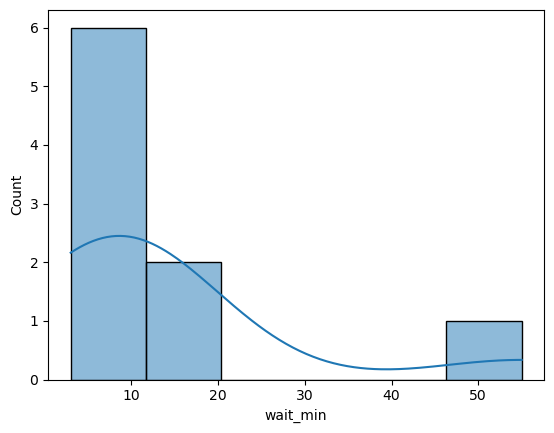

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=clean,
    x="wait_min",
    bins=6,
    kde=True
)

plt.show()

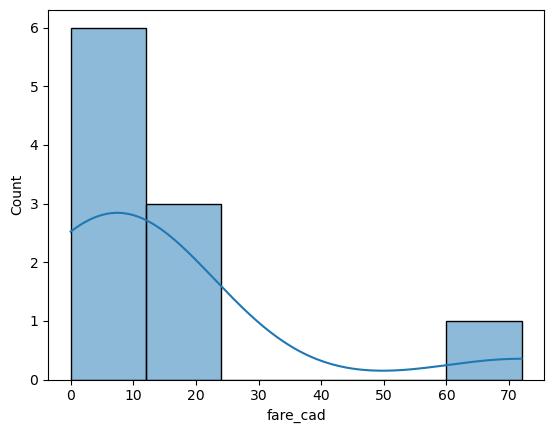

In [10]:
sns.histplot(
    data=clean,
    x="fare_cad",
    bins=6,
    kde=True
)

plt.show()

In [13]:
# Transformation

clean["log_fare"] = np.log1p(
    clean["fare_cad"]
)

clean["log_fare"]

clean["log_wait"] = np.log1p(
    clean["wait_min"]
)

clean["log_wait"]

# Fare and waiting time are strongly right-skewed. 
# A log transformation can reduce the skewness and may be useful for modeling or visualization. 
# However, for descriptive EDA, the original scale should still be reported because dollars and minutes are easier to interpret.

0    3.020425
1    1.558145
2    0.000000
3    2.501436
4    1.558145
5    2.653242
6    0.000000
7    1.558145
8    4.290459
9    2.772589
Name: log_fare, dtype: float64

0    1.945910
1    2.302585
2    1.609438
3    2.564949
4    2.944439
5         NaN
6    1.386294
7    2.484907
8    4.025352
9    2.197225
Name: log_wait, dtype: float64

<Axes: xlabel='wait_min', ylabel='Count'>

Text(0.5, 0, 'Waiting time (minutes)')

Text(0.5, 1.0, 'Distribution of Waiting Time')

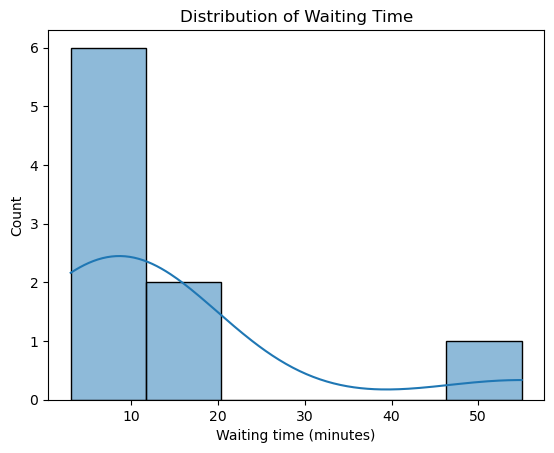

In [14]:
# 5. Create at least three appropriate visualizations and explain what each reveals

# Plot 1 — Waiting-time histogram

sns.histplot(
    data=clean,
    x="wait_min",
    bins=6,
    kde=True
)

plt.xlabel("Waiting time (minutes)")
plt.title("Distribution of Waiting Time")
plt.show()

# Reveals
# Waiting time is strongly right-skewed. Most trips have relatively moderate waits, 
# while T009 has an unusually long waiting time of 55 minutes.

<Axes: xlabel='mode', ylabel='wait_min'>

<Axes: xlabel='mode', ylabel='wait_min'>

Text(0.5, 0, 'Mode')

Text(0, 0.5, 'Waiting time (minutes)')

Text(0.5, 1.0, 'Waiting Time by Transportation Mode')

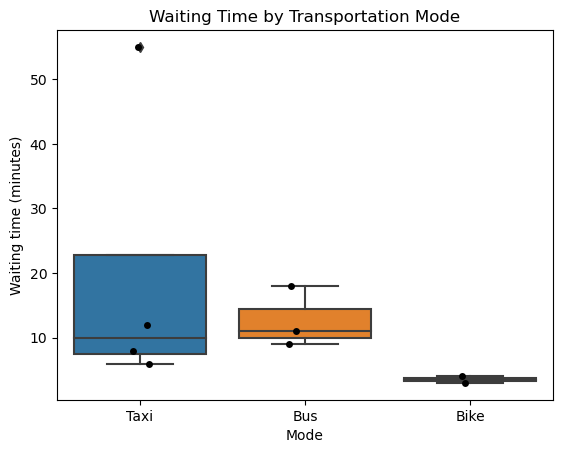

In [15]:
# Plot 2 — Wait time by mode

sns.boxplot(
    data=clean,
    x="mode",
    y="wait_min"
)

sns.stripplot(
    data=clean,
    x="mode",
    y="wait_min",
    color="black"
)

plt.xlabel("Mode")
plt.ylabel("Waiting time (minutes)")
plt.title("Waiting Time by Transportation Mode")
plt.show()

# Reveals
# - Bike waits are consistently short.
# - Bus waits are higher.
# - Taxi shows a very large spread because of the 55-minute observation.
# - Taxi mean alone is therefore misleading.

<Axes: xlabel='distance_km', ylabel='fare_cad'>

Text(0.5, 0, 'Distance (km)')

Text(0, 0.5, 'Fare (CAD)')

Text(0.5, 1.0, 'Trip Distance vs Fare')

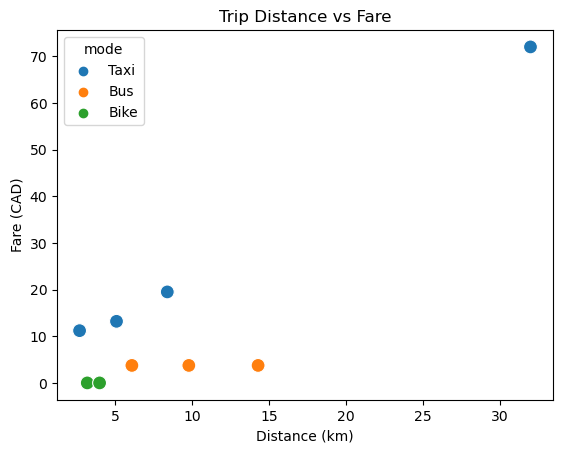

In [16]:
# Plot 3 — Distance vs Fare

sns.scatterplot(
    data=clean,
    x="distance_km",
    y="fare_cad",
    hue="mode",
    s=100
)

plt.xlabel("Distance (km)")
plt.ylabel("Fare (CAD)")
plt.title("Trip Distance vs Fare")
plt.show()

# Reveals
# The plot appears to show a positive relationship between distance and fare, 
# but the relationship is heavily influenced by T009 and also differs across transportation modes.

<Axes: xlabel='peak', ylabel='wait_min'>

<Axes: xlabel='peak', ylabel='wait_min'>

Text(0.5, 0, 'Peak Period')

Text(0, 0.5, 'Waiting time (minutes)')

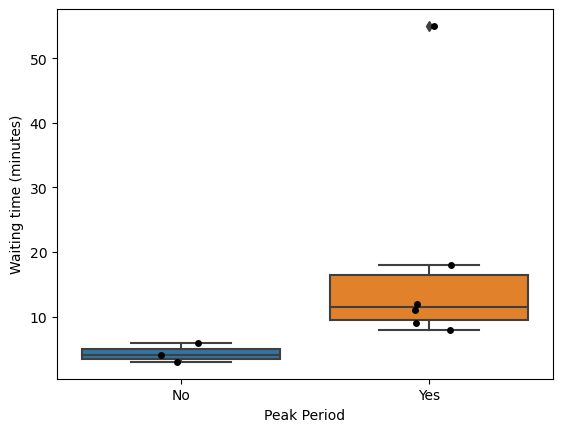

In [17]:
# Plot 4 — Peak vs Off-Peak Wait


sns.boxplot(
    data=clean,
    x="peak",
    y="wait_min"
)

sns.stripplot(
    data=clean,
    x="peak",
    y="wait_min",
    color="black"
)

plt.xlabel("Peak Period")
plt.ylabel("Waiting time (minutes)")
plt.show()